In [1]:
# ============================================================
# Project B: Customer Churn Prediction Project (Logistic Regression)
# ============================================================

# Section 1: Setup & Libraries
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ML libraries
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
from imblearn.over_sampling import SMOTE


In [3]:
# Section 2: Load & Clean Data
# Load dataset
df = pd.read_csv(r"C:\Users\krishna\Downloads\archive (3)\WA_Fn-UseC_-Telco-Customer-Churn.csv")   # Replace with actual Kaggle path

# Inspect
print(df.info())
print(df.describe())
print(df['Churn'].value_counts())

# Handle missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.fillna(df.median(numeric_only=True), inplace=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


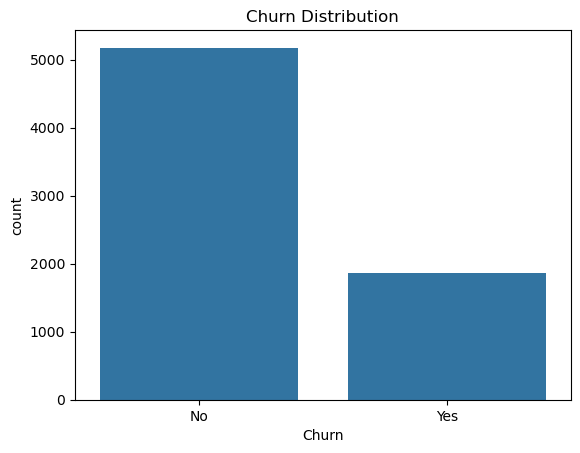

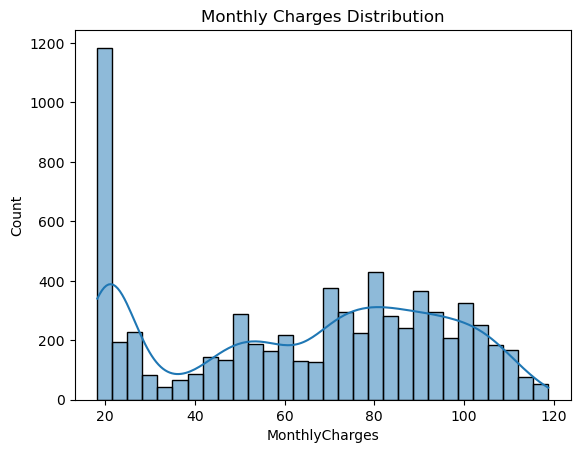

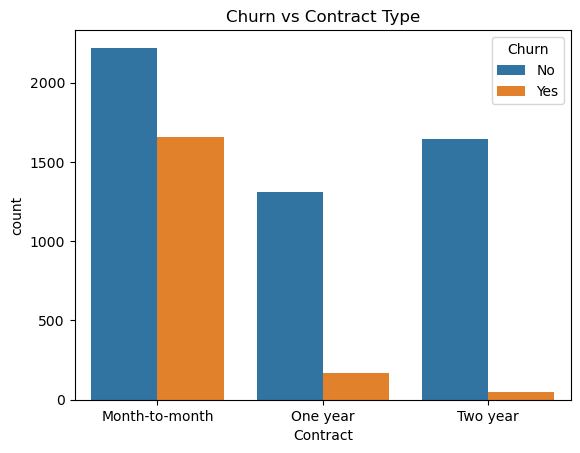

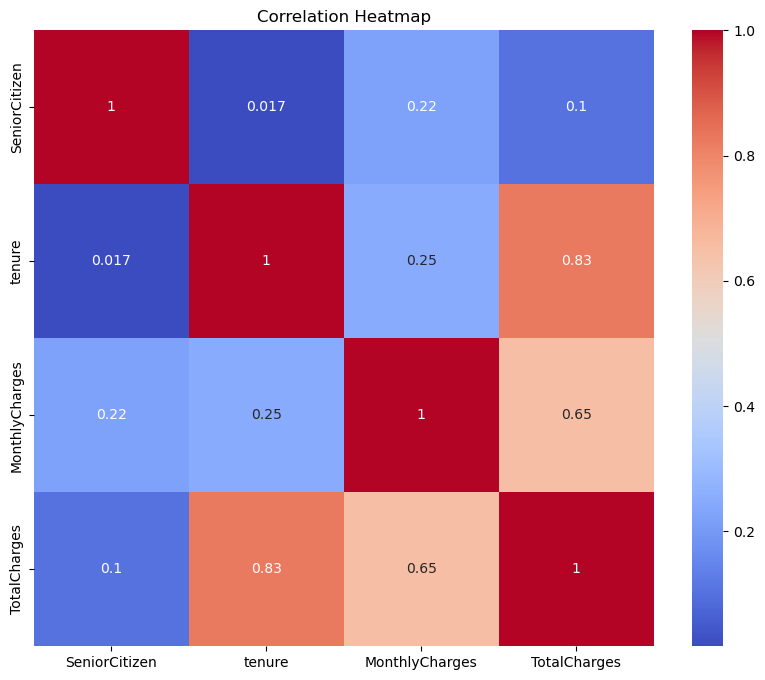

In [4]:
# Section 3: Exploratory Data Analysis (EDA)
# Churn distribution
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

# Histogram: Monthly Charges
sns.histplot(df['MonthlyCharges'], bins=30, kde=True)
plt.title("Monthly Charges Distribution")
plt.show()

# Churn vs Contract Type
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn vs Contract Type")
plt.show()

# Select only numeric columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Correlation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [5]:
# Section 4: Feature Engineering
# Encode categorical variables
df = pd.get_dummies(df, drop_first=True)

# Features & target
X = df.drop("Churn_Yes", axis=1)
y = df["Churn_Yes"]

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Handle class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)


In [6]:
# Section 5: Modeling
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)

# Baseline Logistic Regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred_log = logreg.predict(X_test)

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf_params = {"n_estimators":[100,200], "max_depth":[None,10,20]}
rf_cv = GridSearchCV(rf, rf_params, cv=5)
rf_cv.fit(X_train, y_train)
y_pred_rf = rf_cv.predict(X_test)

# XGBoost
xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_params = {"learning_rate":[0.05,0.1], "max_depth":[3,5,7], "n_estimators":[100,200]}
xgb_cv = GridSearchCV(xgb, xgb_params, cv=5)
xgb_cv.fit(X_train, y_train)
y_pred_xgb = xgb_cv.predict(X_test)


C:\Users\krishna\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:49:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\krishna\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:49:18] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\krishna\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:49:26] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\krishna\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:49:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.up

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Logistic Regression  0.865217   0.794793  0.989514  0.881529  0.990975
1        Random Forest  0.895169   0.890977  0.903718  0.897302  0.961218
2              XGBoost  0.863285   0.864762  0.865586  0.865174  0.942566


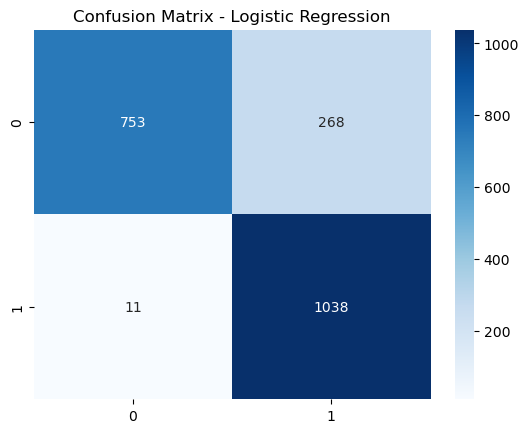

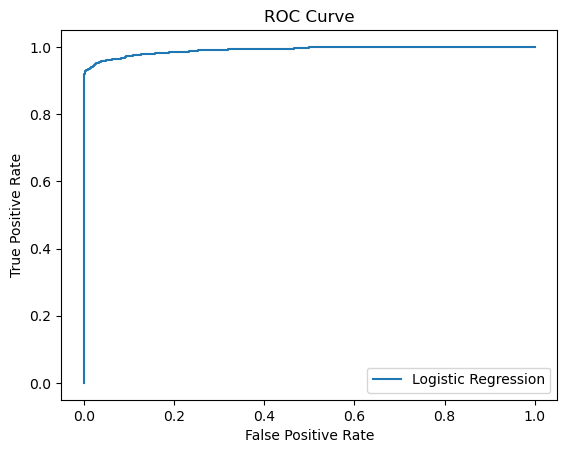

In [7]:
# Section 6: Evaluation
def evaluate_model(name, y_test, y_pred, y_prob=None):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else None
    }

results = []
results.append(evaluate_model("Logistic Regression", y_test, y_pred_log, logreg.predict_proba(X_test)[:,1]))
results.append(evaluate_model("Random Forest", y_test, y_pred_rf, rf_cv.predict_proba(X_test)[:,1]))
results.append(evaluate_model("XGBoost", y_test, y_pred_xgb, xgb_cv.predict_proba(X_test)[:,1]))

results_df = pd.DataFrame(results)
print(results_df)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, logreg.predict_proba(X_test)[:,1])
plt.plot(fpr, tpr, label="Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
